# Causal Relationship Detection Pipeline

End-to-end pipeline for detecting causal relationships between ITSM incidents.

**Purpose:** Detect root-cause relationships to:
- Find which incidents triggered cascading failures
- Link duplicate/related incidents to their root cause
- Build incident dependency graphs
- Improve incident resolution by finding root causes faster

**Sections:**
1. Setup & Configuration
2. Data Loading & Analysis
3. Causal Pair Extraction
4. Non-Causal Pair Generation
5. Data Validation & Review
6. Model Training
7. Model Evaluation
8. Inference & Root Cause Detection

## Section 1: Setup & Configuration

In [1]:
# Cell 1: Imports
import pandas as pd
import numpy as np
import json
import re
from datetime import datetime, timedelta
from pathlib import Path
from tqdm.notebook import tqdm

from sentence_transformers import SentenceTransformer, CrossEncoder, InputExample
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, f1_score, precision_score, recall_score, precision_recall_curve
import matplotlib.pyplot as plt
import seaborn as sns

print("OK Imports successful")

OK Imports successful


In [2]:
# Silver label config (strict): dup>=0.90, rel>=0.80, causal_sim>=0.75, causal_conf>=0.90, temporal_neg_sim<=0.40, embed_neg_sim<=0.50, neg_pos=1.5, embed_neg_limit=2000
# Cell 2: Configuration

# Data paths
DATA_PATH = 'data_new/SNow_incident_ticket_data.csv'
OUTPUT_PATH = 'data/causal_relationship_pairs.json'
MODEL_SAVE_PATH = 'models/causal_classifier/causal_crossencoder_v1'

# Extraction targets
TARGET_CAUSAL = 1000
TARGET_NON_CAUSAL = 3000

# Heuristic thresholds
TEMPORAL_WINDOW_HOURS = 1
SIMILARITY_THRESHOLD = 0.6
CONFIDENCE_THRESHOLD = 0.7

# Category dependencies (upstream -> downstream)
CAUSAL_CATEGORY_PAIRS = {
    'Network': ['Application', 'Database', 'Email'],
    'Server': ['Application', 'Database'],
    'Database': ['Application'],
    'Power': ['Server', 'Network', 'Application'],
    'Storage': ['Database', 'Application']
}

# Training config
BATCH_SIZE = 16
EPOCHS = 3
LEARNING_RATE = 2e-5
MAX_SEQ_LENGTH = 512
RANDOM_SEED = 42
MIN_POS_PER_SPLIT = 20
FALLBACK_TO_STRATIFIED = True
USE_CAUSAL_TAGS = True
USE_META_HINTS = True
USE_SILVER_LABELS = True
SILVER_TEMPORAL_PATH = 'docs/labeling/silver_pairs_temporal_24h_10000.csv'
SILVER_EMBEDDING_PATH = 'docs/labeling/silver_pairs_embedding_neighbors_10000.csv'
USE_SILVER_EMBED_NEGS = False

# Split config (temporal)
TRAIN_TIME_RATIO = 0.70
EVAL_TIME_RATIO = 0.15
DEFAULT_CAUSAL_THRESHOLD = 0.5

print("OK Configuration loaded")
print(f"  Data: {DATA_PATH}")
print(f"  Output: {OUTPUT_PATH}")
print(f"  Model save: {MODEL_SAVE_PATH}")
print(f"  Targets: {TARGET_CAUSAL} causal + {TARGET_NON_CAUSAL} non-causal pairs")

OK Configuration loaded
  Data: data_new/SNow_incident_ticket_data.csv
  Output: data/causal_relationship_pairs.json
  Model save: models/causal_classifier/causal_crossencoder_v1
  Targets: 1000 causal + 3000 non-causal pairs


## Section 2: Data Loading & Analysis

In [3]:
# Cell 3: Load Data
print("Loading ServiceNow incident data...")
df = pd.read_csv(DATA_PATH, encoding='utf-8-sig')

# Basic schema validation
required_cols = ['Number', 'Description', 'Created', 'Closed', 'Resolution notes', 'Category']
missing_cols = [col for col in required_cols if col not in df.columns]
if missing_cols:
    raise ValueError(f"Missing required columns: {missing_cols}")
# Parse timestamps
df['Created_dt'] = pd.to_datetime(df['Created'], errors='coerce')
df['Closed_dt'] = pd.to_datetime(df['Closed'], errors='coerce')

# Sort by creation time
df = df.sort_values('Created_dt').reset_index(drop=True)

print(f"Total incidents: {len(df):,}")
print(f"Date range: {df['Created_dt'].min()} to {df['Created_dt'].max()}")
print(f"\nAvailable columns:")
print(df.columns.tolist())

Loading ServiceNow incident data...


C:\Users\donov\AppData\Local\Temp\ipykernel_2828\3981858280.py:11: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Created_dt'] = pd.to_datetime(df['Created'], errors='coerce')
C:\Users\donov\AppData\Local\Temp\ipykernel_2828\3981858280.py:12: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Closed_dt'] = pd.to_datetime(df['Closed'], errors='coerce')


Total incidents: 10,633
Date range: 2024-01-04 09:40:00 to 2025-12-08 23:08:00

Available columns:
['Number', 'Description', 'Opened by', 'Company', 'ITSM Department', 'Created', 'Urgency', 'Impact', 'Priority', 'Assignment group', 'Assigned to', 'State', 'Service', 'Service offering', 'Closed', 'Closed by', 'Category', 'Subcategory', 'Resolution code', 'Resolution notes', 'User input', 'Comments and Work notes', 'Manday Effort (hrs)', 'Ticket Type', 'AMS Domain', 'AMS System Type', 'AMS Category Type', 'AMS Service Type', 'AMS Business Related', 'AMS IT Related', 'Created_dt', 'Closed_dt']


In [4]:
# Cell 4: Analyze Fields for Causality

# Check for parent/child fields
parent_fields = [col for col in df.columns if 'parent' in col.lower() or 'caused' in col.lower()]
print(f"Parent/child fields: {parent_fields}")

# Check resolution notes
has_resolution = df['Resolution notes'].notna().sum()
print(f"\nIncidents with resolution notes: {has_resolution:,} ({has_resolution/len(df)*100:.1f}%)")

# Category distribution
print("\nTop categories:")
print(df['Category'].value_counts().head(10))

# Check for incident number references in resolution notes
print("\nSample resolution notes with incident references:")
for idx, row in df[df['Resolution notes'].notna()].head(20).iterrows():
    res_notes = str(row['Resolution notes'])
    if re.search(r'INC\d{7}', res_notes):
        print(f"  {row['Number']}: {res_notes[:150]}...")
        break

Parent/child fields: []

Incidents with resolution notes: 10,349 (97.3%)

Top categories:
Category
Application/Software    9570
Network                  372
Server                   123
Hardware                   5
Name: count, dtype: int64

Sample resolution notes with incident references:


## Section 3: Causal Pair Extraction

Three extraction methods:
1. **Parent/Child References**: Explicit parent incident fields (confidence: 0.95)
2. **Resolution Note Mining**: Pattern matching for causal mentions (confidence: 0.7-0.9)
3. **Temporal + Similarity**: Time window + semantic similarity + category dependencies (confidence: 0.6-0.8)

In [5]:
# Cell 5: Method 1 - Parent/Child References

def extract_parent_child_pairs(df):
    """Extract causal pairs from explicit parent/child incident fields."""
    causal_pairs = []

    # Find fields containing parent/child references
    ref_fields = [col for col in df.columns if any(kw in col.lower() for kw in ['parent', 'caused', 'related'])]
    
    if not ref_fields:
        print("No parent/child reference fields found")
        return causal_pairs

    print(f"Searching fields: {ref_fields}")

    for idx, row in tqdm(df.iterrows(), total=len(df), desc="Extracting parent/child"):
        for field in ref_fields:
            if pd.notna(row[field]):
                # Parse incident ID (INCxxxxxxx format)
                matches = re.findall(r'INC(\d{7})', str(row[field]))
                for match in matches:
                    parent_id = f'INC{match}'
                    parent_row = df[df['Number'] == parent_id]

                    if not parent_row.empty:
                        parent_idx = parent_row.index[0]

                        # Verify temporal ordering
                        if pd.notna(df.loc[parent_idx, 'Created_dt']) and pd.notna(row['Created_dt']):
                            if df.loc[parent_idx, 'Created_dt'] < row['Created_dt']:
                                causal_pairs.append({
                                    'incident_a_id': parent_id,
                                    'incident_b_id': row['Number'],
                                    'text_a': str(df.loc[parent_idx, 'Description']),
                                    'text_b': str(row['Description']),
                                    'label': 'causal',
                                    'confidence': 0.95,
                                    'evidence': ['parent_child_ref', field]
                                })

    return causal_pairs

parent_child_pairs = extract_parent_child_pairs(df)
print(f"\nOK Extracted {len(parent_child_pairs)} parent/child pairs")

Searching fields: ['AMS Business Related', 'AMS IT Related']


Extracting parent/child:   0%|          | 0/10633 [00:00<?, ?it/s]


OK Extracted 0 parent/child pairs


In [6]:
# Cell 6: Method 2 - Resolution Note Mining

def extract_from_resolution_notes(df):
    """Mine resolution notes for causal mentions."""
    patterns = [
        (r'(?i)root\s+cause[:\s]+(INC\d{7})', 0.9),
        (r'(?i)caused\s+by[:\s]+(INC\d{7})', 0.85),
        (r'(?i)due\s+to[:\s]+(INC\d{7})', 0.8),
        (r'(?i)triggered\s+by[:\s]+(INC\d{7})', 0.8),
        (r'(?i)same\s+issue\s+as[:\s]+(INC\d{7})', 0.7),
        (r'(?i)related\s+to[:\s]+(INC\d{7})', 0.7),
    ]

    causal_pairs = []

    for idx, row in tqdm(df.iterrows(), total=len(df), desc="Mining resolution notes"):
        if pd.notna(row['Resolution notes']):
            res_notes = str(row['Resolution notes'])

            for pattern, conf in patterns:
                matches = re.findall(pattern, res_notes)
                for match in matches:
                    cause_id = match
                    cause_row = df[df['Number'] == cause_id]

                    if not cause_row.empty:
                        cause_idx = cause_row.index[0]

                        # Verify temporal ordering
                        if pd.notna(df.loc[cause_idx, 'Created_dt']) and pd.notna(row['Created_dt']):
                            if df.loc[cause_idx, 'Created_dt'] < row['Created_dt']:
                                causal_pairs.append({
                                    'incident_a_id': cause_id,
                                    'incident_b_id': row['Number'],
                                    'text_a': str(df.loc[cause_idx, 'Description']),
                                    'text_b': str(row['Description']),
                                    'label': 'causal',
                                    'confidence': conf,
                                    'evidence': ['resolution_note', pattern]
                                })

    return causal_pairs

resolution_pairs = extract_from_resolution_notes(df)
print(f"\nOK Extracted {len(resolution_pairs)} pairs from resolution notes")

Mining resolution notes:   0%|          | 0/10633 [00:00<?, ?it/s]


OK Extracted 1 pairs from resolution notes


In [7]:
# Cell 7: Load Embeddings for Similarity (V4 Cosine Model)

# Load pre-computed V4 embeddings if available, otherwise generate
print("Loading/generating V4 embeddings...")

try:
    embeddings = np.load('embeddings_v4_cache.npy')
    print(f"OK Loaded cached V4 embeddings: {embeddings.shape}")
except:
    print("Generating V4 embeddings (this may take 10-15 minutes)...")
    
    # Load YOUR trained V4 model
    import sys
    sys.path.insert(0, str(Path.cwd() / 'notebook-fixes'))
    from deploy_model_v4 import V4CosineModelDeployment
    
    # Initialize V4 model
    v4_model = V4CosineModelDeployment()
    print(f"V4 Model loaded: {v4_model.model.get_sentence_embedding_dimension()}-dim embeddings")
    
    # Generate embeddings
    texts = df['Description'].fillna('').tolist()
    embeddings = v4_model.encode(texts, show_progress_bar=True, batch_size=32)
    
    # Save cache
    np.save('embeddings_v4_cache.npy', embeddings)
    print(f"OK Saved V4 embeddings: {embeddings.shape}")

Loading/generating V4 embeddings...
OK Loaded cached V4 embeddings: (10633, 768)


In [8]:
# Cell 8: Method 3 - Temporal + Similarity

def generate_temporal_causal_candidates(df, embeddings, max_candidates=500):
    """Find temporally close + semantically similar incidents."""
    candidates = []

    for idx in tqdm(range(len(df)), desc="Temporal clustering"):
        if pd.isna(df.loc[idx, 'Created_dt']):
            continue
            
        current_time = df.loc[idx, 'Created_dt']
        window_end = current_time + timedelta(hours=TEMPORAL_WINDOW_HOURS)

        # Find incidents within time window
        mask = (df['Created_dt'] > current_time) & (df['Created_dt'] <= window_end)
        window_indices = df[mask].index.tolist()

        if not window_indices:
            continue

        # Compute similarities
        current_emb = embeddings[idx]
        window_embs = embeddings[window_indices]
        similarities = np.dot(window_embs, current_emb)

        # Filter by similarity threshold
        high_sim = similarities > SIMILARITY_THRESHOLD

        for i, win_idx in enumerate(window_indices):
            if high_sim[i]:
                # Apply category dependency scoring
                score = similarities[i]

                cat_a = df.loc[idx, 'Category']
                cat_b = df.loc[win_idx, 'Category']

                # Boost score if category dependency exists
                if pd.notna(cat_a) and pd.notna(cat_b):
                    if cat_a in CAUSAL_CATEGORY_PAIRS:
                        if cat_b in CAUSAL_CATEGORY_PAIRS[cat_a]:
                            score += 0.2

                candidates.append({
                    'incident_a_id': df.loc[idx, 'Number'],
                    'incident_b_id': df.loc[win_idx, 'Number'],
                    'text_a': str(df.loc[idx, 'Description']),
                    'text_b': str(df.loc[win_idx, 'Description']),
                    'label': 'causal',
                    'confidence': min(score, 1.0),
                    'evidence': ['temporal_proximity', 'semantic_similarity']
                })

        if len(candidates) >= max_candidates:
            break

    # Sort by confidence, return top candidates
    candidates.sort(key=lambda x: x['confidence'], reverse=True)
    return candidates[:max_candidates]

temporal_candidates = generate_temporal_causal_candidates(df, embeddings)
print(f"\nOK Generated {len(temporal_candidates)} temporal + similarity candidates")

Temporal clustering:   0%|          | 0/10633 [00:00<?, ?it/s]


OK Generated 500 temporal + similarity candidates


In [9]:
# Cell 9: Combine & Deduplicate Causal Pairs

def deduplicate_pairs(pairs):
    """Remove duplicate pairs, keeping highest confidence."""
    seen = {}
    for pair in pairs:
        key = (pair['incident_a_id'], pair['incident_b_id'])
        if key not in seen or pair['confidence'] > seen[key]['confidence']:
            seen[key] = pair
    return list(seen.values())

# Combine all extraction methods
all_causal = parent_child_pairs + resolution_pairs + temporal_candidates
all_causal = deduplicate_pairs(all_causal)

# Sort by confidence
all_causal.sort(key=lambda x: x['confidence'], reverse=True)

# Take top TARGET_CAUSAL
causal_pairs = all_causal[:TARGET_CAUSAL]

print(f"\nTotal unique causal pairs: {len(all_causal)}")
print(f"Selected for training: {len(causal_pairs)}")
print(f"\nConfidence distribution:")
confidences = [p['confidence'] for p in causal_pairs]
print(f"  High (>0.8): {sum(1 for c in confidences if c > 0.8)}")
print(f"  Medium (0.6-0.8): {sum(1 for c in confidences if 0.6 <= c <= 0.8)}")
print(f"  Low (<0.6): {sum(1 for c in confidences if c < 0.6)}")


Total unique causal pairs: 501
Selected for training: 501

Confidence distribution:
  High (>0.8): 263
  Medium (0.6-0.8): 238
  Low (<0.6): 0


## Section 4: Non-Causal Pair Generation

Generate balanced negative examples:
- 30% Random pairs
- 30% Same category, distant time
- 40% Low similarity

In [10]:
# Cell 10: Generate Non-Causal Pairs

def generate_non_causal_pairs(df, causal_pairs, embeddings, count=3000):
    """Generate balanced negative examples."""
    non_causal = []

    # Track causal pairs to avoid false negatives
    causal_pair_set = set()
    for p in causal_pairs:
        causal_pair_set.add((p['incident_a_id'], p['incident_b_id']))
        causal_pair_set.add((p['incident_b_id'], p['incident_a_id']))

    # Track generated pairs to avoid duplicates
    seen_pairs = set()

    def add_pair_direct(a_id, b_id, text_a, text_b, evidence):
        pair_key = (a_id, b_id)
        if pair_key in causal_pair_set or pair_key in seen_pairs:
            return False
        non_causal.append({
            'incident_a_id': a_id,
            'incident_b_id': b_id,
            'text_a': str(text_a),
            'text_b': str(text_b),
            'label': 'non-causal',
            'confidence': 1.0,
            'evidence': [evidence]
        })
        seen_pairs.add(pair_key)
        return True

    # Type 0: Reverse causal pairs (directionality negatives)
    reverse_added = 0
    for p in causal_pairs:
        if add_pair_direct(p['incident_b_id'], p['incident_a_id'], p['text_b'], p['text_a'], 'reverse_causal'):
            reverse_added += 1
    if reverse_added:
        print(f"OK Generated {reverse_added} reverse-direction negatives")

    def add_pair(idx_a, idx_b, evidence):
        if idx_a == idx_b:
            return False
        a_id = df.loc[idx_a, 'Number']
        b_id = df.loc[idx_b, 'Number']
        pair_key = (a_id, b_id)

        if pair_key in causal_pair_set or pair_key in seen_pairs:
            return False

        non_causal.append({
            'incident_a_id': a_id,
            'incident_b_id': b_id,
            'text_a': str(df.loc[idx_a, 'Description']),
            'text_b': str(df.loc[idx_b, 'Description']),
            'label': 'non-causal',
            'confidence': 1.0,
            'evidence': [evidence]
        })
        seen_pairs.add(pair_key)
        return True

    remaining = max(0, count - len(non_causal))

    # Type 1: Random pairs (30% of remaining)
    random_count = int(remaining * 0.3)
    attempts = 0
    random_added = 0
    while random_added < random_count and attempts < random_count * 10 and len(non_causal) < count:
        idx_a, idx_b = np.random.choice(len(df), 2, replace=False)
        attempts += 1

        if add_pair(idx_a, idx_b, 'random_pair'):
            random_added += 1

    print(f"OK Generated {random_added} random negatives")

    # Type 2: Same category, different time (30% of remaining)
    same_cat_count = int(remaining * 0.3)
    categories = df['Category'].dropna().unique()
    attempts = 0
    same_cat_added = 0

    while same_cat_added < same_cat_count and attempts < same_cat_count * 10 and len(non_causal) < count:
        cat = np.random.choice(categories)
        cat_df = df[df['Category'] == cat]
        attempts += 1

        if len(cat_df) >= 2:
            idx_a, idx_b = np.random.choice(cat_df.index, 2, replace=False)

            # Ensure >24 hours apart
            if pd.notna(df.loc[idx_a, 'Created_dt']) and pd.notna(df.loc[idx_b, 'Created_dt']):
                time_diff = abs((df.loc[idx_a, 'Created_dt'] - df.loc[idx_b, 'Created_dt']).total_seconds())
                if time_diff > 24 * 3600:
                    if add_pair(idx_a, idx_b, 'same_category_distant_time'):
                        same_cat_added += 1

    print(f"OK Generated {same_cat_added} same category negatives")

    # Type 3: Low similarity (remaining)
    low_sim_count = max(0, count - len(non_causal))
    attempts = 0
    low_sim_added = 0

    while low_sim_added < low_sim_count and attempts < low_sim_count * 10 and len(non_causal) < count:
        idx_a = np.random.randint(0, len(df))
        emb_a = embeddings[idx_a]
        attempts += 1

        # Find low similarity incidents
        similarities = np.dot(embeddings, emb_a)
        low_sim_indices = np.where(similarities < 0.3)[0]

        if len(low_sim_indices) > 0:
            idx_b = np.random.choice(low_sim_indices)
            if add_pair(idx_a, idx_b, 'low_similarity'):
                low_sim_added += 1

    print(f"OK Generated {low_sim_added} low similarity negatives")

    return non_causal[:count]

non_causal_pairs = generate_non_causal_pairs(df, causal_pairs, embeddings, count=TARGET_NON_CAUSAL)
print(f"\nOK Total generated: {len(non_causal_pairs)} non-causal pairs")

OK Generated 900 random negatives
OK Generated 900 same category negatives
OK Generated 1200 low similarity negatives

OK Total generated: 3000 non-causal pairs


## Section 5: Data Validation & Review

In [11]:
# Cell 10b: Override with Silver Labels (Optional)

if USE_SILVER_LABELS:
    generated_causal_pairs = list(causal_pairs)
    generated_non_causal_pairs = list(non_causal_pairs)

    silver_temporal = pd.read_csv(SILVER_TEMPORAL_PATH)
    silver_embed = pd.read_csv(SILVER_EMBEDDING_PATH) if USE_SILVER_EMBED_NEGS else None

    def make_pair(row, label, confidence, evidence, swap=False):
        a_id = row['incident_a_id']
        b_id = row['incident_b_id']
        text_a = row['description_a']
        text_b = row['description_b']
        if swap:
            a_id, b_id = b_id, a_id
            text_a, text_b = text_b, text_a
        return {
            'incident_a_id': a_id,
            'incident_b_id': b_id,
            'text_a': str(text_a),
            'text_b': str(text_b),
            'label': label,
            'confidence': float(confidence),
            'evidence': evidence,
        }

    causal_rows = silver_temporal[silver_temporal['label_causal_direction'].isin(['A->B', 'B->A'])]
    causal_pairs = []
    for _, row in causal_rows.iterrows():
        direction = row['label_causal_direction']
        conf = row.get('label_confidence', 0.5)
        swap = direction == 'B->A'
        causal_pairs.append(make_pair(row, 'causal', conf, ['silver_temporal', 'weak_label', direction], swap=swap))

    non_causal_rows = silver_temporal[~silver_temporal.index.isin(causal_rows.index)]
    non_causal_pairs = []
    for _, row in non_causal_rows.iterrows():
        conf = row.get('label_confidence', 0.5)
        non_causal_pairs.append(make_pair(row, 'non-causal', conf, ['silver_temporal', 'weak_label']))

    if silver_embed is not None:
        for _, row in silver_embed.iterrows():
            conf = row.get('label_confidence', 0.5)
            non_causal_pairs.append(make_pair(row, 'non-causal', conf, ['silver_embedding', 'weak_label']))

    # Sort and cap to targets
    causal_pairs.sort(key=lambda x: x['confidence'], reverse=True)
    if len(causal_pairs) > TARGET_CAUSAL:
        causal_pairs = causal_pairs[:TARGET_CAUSAL]
    if len(causal_pairs) < TARGET_CAUSAL:
        fill = generated_causal_pairs[: max(0, TARGET_CAUSAL - len(causal_pairs))]
        causal_pairs.extend(fill)

    if len(non_causal_pairs) > TARGET_NON_CAUSAL:
        non_causal_pairs = non_causal_pairs[:TARGET_NON_CAUSAL]
    if len(non_causal_pairs) < TARGET_NON_CAUSAL:
        fill = generated_non_causal_pairs[: max(0, TARGET_NON_CAUSAL - len(non_causal_pairs))]
        non_causal_pairs.extend(fill)

    extraction_methods = ['silver_temporal', 'silver_embedding'] if USE_SILVER_EMBED_NEGS else ['silver_temporal']
    print(f'Using silver labels: causal={len(causal_pairs)}, non-causal={len(non_causal_pairs)}')


Using silver labels: causal=990, non-causal=3000


In [12]:
# Cell 11: Save Dataset

import numpy as np

def convert_np(obj):
    """Recursively convert numpy types to native Python types."""
    if isinstance(obj, dict):
        return {k: convert_np(v) for k, v in obj.items()}
    elif isinstance(obj, list):
        return [convert_np(v) for v in obj]
    elif isinstance(obj, np.generic):
        return obj.item()
    else:
        return obj

# Combine and save
if 'extraction_methods' not in globals():
    extraction_methods = ['parent_child', 'resolution_notes', 'temporal_similarity']
all_pairs = causal_pairs + non_causal_pairs

dataset = {
    'total_pairs': len(all_pairs),
    'causal_count': len(causal_pairs),
    'non_causal_count': len(non_causal_pairs),
    'extraction_methods': extraction_methods,
    'pairs': all_pairs
}

# Convert all numpy types to native types before saving
dataset = convert_np(dataset)

# Create directory if needed
Path(OUTPUT_PATH).parent.mkdir(parents=True, exist_ok=True)

with open(OUTPUT_PATH, 'w') as f:
    json.dump(dataset, f, indent=2)

print(f"OK Saved {len(all_pairs)} pairs to {OUTPUT_PATH}")
print(f"  Causal: {len(causal_pairs)}")
print(f"  Non-causal: {len(non_causal_pairs)}")

OK Saved 3990 pairs to data/causal_relationship_pairs.json
  Causal: 990
  Non-causal: 3000


In [13]:
# Cell 12: Review Samples

print("="*80)
print("SAMPLE CAUSAL PAIRS (High Confidence)")
print("="*80)

for i, pair in enumerate(causal_pairs[:5], 1):
    print(f"\n{i}. Confidence: {pair['confidence']:.2f} | Evidence: {pair['evidence']}")
    print(f"   A ({pair['incident_a_id']}): {pair['text_a'][:100]}...")
    print(f"   B ({pair['incident_b_id']}): {pair['text_b'][:100]}...")

print("\n" + "="*80)
print("SAMPLE NON-CAUSAL PAIRS")
print("="*80)

for i, pair in enumerate(non_causal_pairs[:3], 1):
    print(f"\n{i}. Evidence: {pair['evidence']}")
    print(f"   A ({pair['incident_a_id']}): {pair['text_a'][:100]}...")
    print(f"   B ({pair['incident_b_id']}): {pair['text_b'][:100]}...")

SAMPLE CAUSAL PAIRS (High Confidence)

1. Confidence: 0.95 | Evidence: ['silver_temporal', 'weak_label', 'A->B']
   A (INC0066135): Dear Team

Error occurred while processing the EDI transaction. Please find the details below and at...
   B (INC0066292): Dear Team

Error occurred while processing the EDI transaction. Please find the details below and at...

2. Confidence: 0.95 | Evidence: ['silver_temporal', 'weak_label', 'A->B']
   A (INC0051956): Dear Team

Error occurred while processing the EDI transaction

Interface       mcrm-tracking-event
...
   B (INC0051963): Please help to check eTR-S1-25000026, currently in post stage.

However user realise under ENT-01 ...

3. Confidence: 0.95 | Evidence: ['silver_temporal', 'weak_label', 'A->B']
   A (INC0055856): 1.	Invoicing at correct rate and quantity - We noted the following:
a.	– For billing type “YBIL” pr...
   B (INC0055917): cannot reset sap pass...

4. Confidence: 0.95 | Evidence: ['silver_temporal', 'weak_label', 'A->B']
   A (

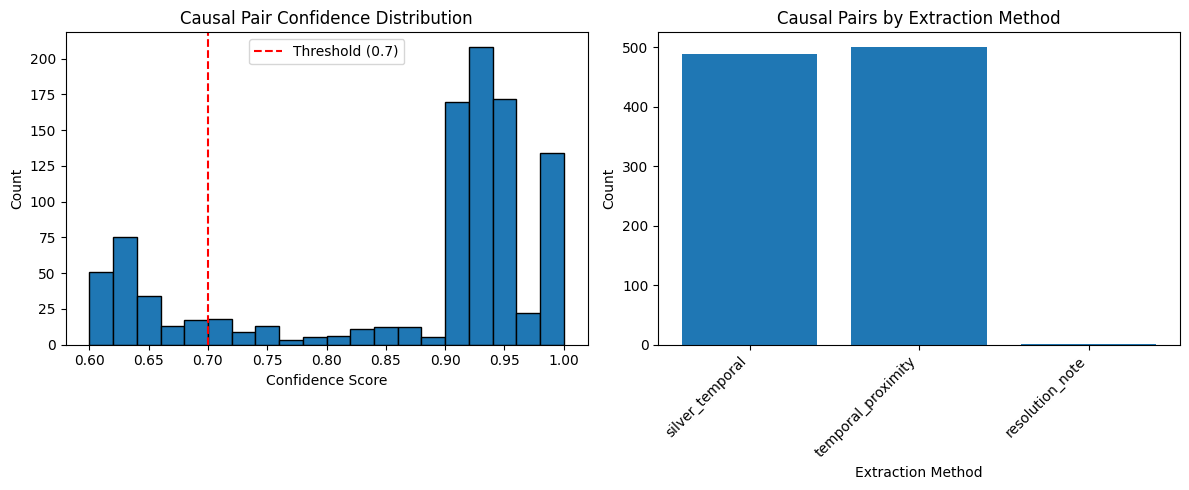


Extraction method breakdown:
  silver_temporal: 489 (49.4%)
  temporal_proximity: 500 (50.5%)
  resolution_note: 1 (0.1%)


In [14]:
# Cell 13: Visualize Confidence Distribution

plt.figure(figsize=(12, 5))

# Plot 1: Confidence distribution
plt.subplot(1, 2, 1)
confidences = [p['confidence'] for p in causal_pairs]
plt.hist(confidences, bins=20, edgecolor='black')
plt.xlabel('Confidence Score')
plt.ylabel('Count')
plt.title('Causal Pair Confidence Distribution')
plt.axvline(x=CONFIDENCE_THRESHOLD, color='r', linestyle='--', label=f'Threshold ({CONFIDENCE_THRESHOLD})')
plt.legend()

# Plot 2: Evidence method distribution
plt.subplot(1, 2, 2)
evidence_counts = {}
for pair in causal_pairs:
    method = pair['evidence'][0]
    evidence_counts[method] = evidence_counts.get(method, 0) + 1

plt.bar(evidence_counts.keys(), evidence_counts.values())
plt.xlabel('Extraction Method')
plt.ylabel('Count')
plt.title('Causal Pairs by Extraction Method')
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

print(f"\nExtraction method breakdown:")
for method, count in evidence_counts.items():
    print(f"  {method}: {count} ({count/len(causal_pairs)*100:.1f}%)")

## Section 6: Model Training

In [15]:
# Cell 14: Prepare Training Data

from transformers import AutoTokenizer

# Tokenizer for truncation to avoid >512 token warnings
tokenizer = AutoTokenizer.from_pretrained('cross-encoder/ms-marco-MiniLM-L-12-v2')

def truncate_text(text):
    if text is None:
        return ""
    encoded = tokenizer(str(text), truncation=True, max_length=MAX_SEQ_LENGTH, return_tensors=None)
    return tokenizer.decode(encoded["input_ids"], skip_special_tokens=True)

def format_pair(text_a, text_b, meta=None):
    return truncate_pair(text_a, text_b, meta)

def truncate_pair(text_a, text_b, meta=None):
    if text_a is None:
        text_a = ""
    if text_b is None:
        text_b = ""
    text_a = str(text_a)
    text_b = str(text_b)
    if USE_META_HINTS and meta:
        cat_a = meta.get("cat_a")
        cat_b = meta.get("cat_b")
        delta_hours = meta.get("delta_hours")
        if cat_a:
            text_a = f"{text_a} | CAT: {cat_a}"
        if cat_b:
            text_b = f"{text_b} | CAT: {cat_b}"
        if delta_hours is not None:
            text_b = f"{text_b} | DELTA_HOURS: {delta_hours:.2f}"
    if USE_CAUSAL_TAGS:
        text_a = f"CAUSE: {text_a}"
        text_b = f"EFFECT: {text_b}"
    encoded = tokenizer(
        text_a,
        text_b,
        truncation=True,
        max_length=MAX_SEQ_LENGTH,
        return_tensors=None,
    )
    input_ids = encoded["input_ids"]
    sep_id = tokenizer.sep_token_id
    cls_id = tokenizer.cls_token_id
    try:
        first_sep = input_ids.index(sep_id)
        second_sep = input_ids.index(sep_id, first_sep + 1)
    except ValueError:
        decoded = tokenizer.decode(input_ids, skip_special_tokens=True)
        return decoded, ""
    start = 1 if input_ids and input_ids[0] == cls_id else 0
    text_a_ids = input_ids[start:first_sep]
    text_b_ids = input_ids[first_sep + 1:second_sep]
    return (
        tokenizer.decode(text_a_ids, skip_special_tokens=True),
        tokenizer.decode(text_b_ids, skip_special_tokens=True),
    )

def strip_causal_tag(text):
    if text is None:
        return ""
    text = str(text)
    lowered = text.lower()
    for prefix in ("cause:", "cause :", "effect:", "effect :"):
        if lowered.startswith(prefix):
            return text[len(prefix):].lstrip()
    return text

def make_meta(a_time, b_time, cat_a=None, cat_b=None):
    if pd.isna(a_time) or pd.isna(b_time):
        delta_hours = None
    else:
        delta_hours = (b_time - a_time).total_seconds() / 3600
    return {"delta_hours": delta_hours, "cat_a": cat_a, "cat_b": cat_b}

# Create training examples with temporal split
id_to_created = dict(zip(df['Number'], df['Created_dt']))
id_to_category = dict(zip(df['Number'], df['Category']))
pairs_with_time = []
skipped_pairs = 0

for pair in all_pairs:
    label = 1 if pair['label'] == 'causal' else 0
    a_id = pair['incident_a_id']
    b_id = pair['incident_b_id']
    a_time = id_to_created.get(a_id)
    b_time = id_to_created.get(b_id)
    cat_a = id_to_category.get(a_id)
    cat_b = id_to_category.get(b_id)
    if pd.isna(a_time) or pd.isna(b_time):
        skipped_pairs += 1
        continue
    if label == 1 and a_time == b_time:
        skipped_pairs += 1
        continue
    text_a_raw = pair['text_a']
    text_b_raw = pair['text_b']
    if label == 1 and a_time > b_time:
        a_id, b_id = b_id, a_id
        a_time, b_time = b_time, a_time
        cat_a, cat_b = cat_b, cat_a
        text_a_raw, text_b_raw = pair['text_b'], pair['text_a']
    meta = make_meta(a_time, b_time, cat_a, cat_b)
    text_a, text_b = format_pair(text_a_raw, text_b_raw, meta)
    pair_time = max(a_time, b_time)
    pairs_with_time.append((pair_time, text_a, text_b, label))

pair_times = np.array([p[0] for p in pairs_with_time])
pos_times = np.array([p[0] for p in pairs_with_time if p[3] == 1])
cutoff_mode = "quantile"
train_cutoff = np.quantile(pair_times, TRAIN_TIME_RATIO)
eval_cutoff = np.quantile(pair_times, TRAIN_TIME_RATIO + EVAL_TIME_RATIO)

# Adjust cutoffs to guarantee positives in eval/holdout when possible
if len(pos_times) >= MIN_POS_PER_SPLIT * 3:
    pos_times_sorted = np.sort(pos_times)
    eval_cutoff = pos_times_sorted[-MIN_POS_PER_SPLIT]
    train_cutoff = pos_times_sorted[-2 * MIN_POS_PER_SPLIT]
    cutoff_mode = "pos_count"

train_data = []
eval_data = []
holdout_data = []
split_mode = "temporal"

for pair_time, text_a, text_b, label in pairs_with_time:
    ex = InputExample(texts=[text_a, text_b], label=float(label))
    if pair_time <= train_cutoff:
        train_data.append(ex)
    elif pair_time <= eval_cutoff:
        eval_data.append(ex)
    else:
        holdout_data.append(ex)

def count_pos(examples):
    return sum(1 for ex in examples if ex.label == 1.0)

train_pos = count_pos(train_data)
eval_pos = count_pos(eval_data)
holdout_pos = count_pos(holdout_data)

temporal_train_data = list(train_data)
temporal_eval_data = list(eval_data)
temporal_holdout_data = list(holdout_data)

if FALLBACK_TO_STRATIFIED and (eval_pos < MIN_POS_PER_SPLIT or holdout_pos < MIN_POS_PER_SPLIT):
    print("Warning: temporal split has too few positives; falling back to stratified split.")
    split_mode = "stratified"
    all_examples = [InputExample(texts=[p[1], p[2]], label=float(p[3])) for p in pairs_with_time]
    all_labels = np.array([ex.label for ex in all_examples])
    train_data, temp_data = train_test_split(
        all_examples,
        test_size=(1 - TRAIN_TIME_RATIO),
        random_state=RANDOM_SEED,
        stratify=all_labels,
    )
    temp_labels = np.array([ex.label for ex in temp_data])
    eval_ratio = EVAL_TIME_RATIO / (EVAL_TIME_RATIO + (1 - TRAIN_TIME_RATIO - EVAL_TIME_RATIO))
    eval_data, holdout_data = train_test_split(
        temp_data,
        test_size=(1 - eval_ratio),
        random_state=RANDOM_SEED,
        stratify=temp_labels,
    )
    train_pos = count_pos(train_data)
    eval_pos = count_pos(eval_data)
    holdout_pos = count_pos(holdout_data)

print(f"Training samples: {len(train_data)}")
print(f"Evaluation samples: {len(eval_data)}")
print(f"Holdout samples: {len(holdout_data)}")
print(f"Split mode: {split_mode}")
print(f"Skipped pairs (missing timestamps): {skipped_pairs}")
print(f"Train cutoff: {train_cutoff}")
print(f"Eval cutoff: {eval_cutoff}")
print(f"Cutoff mode: {cutoff_mode}")

# Distribution check
train_causal = sum(1 for ex in train_data if ex.label == 1.0)
eval_causal = sum(1 for ex in eval_data if ex.label == 1.0)
holdout_causal = sum(1 for ex in holdout_data if ex.label == 1.0)

print(f"\nCausal distribution:")
print(f"  Train: {train_causal}/{len(train_data)} ({train_causal/len(train_data)*100:.1f}%)")
print(f"  Eval: {eval_causal}/{len(eval_data)} ({eval_causal/len(eval_data)*100:.1f}%)")
print(f"  Holdout: {holdout_causal}/{len(holdout_data)} ({holdout_causal/len(holdout_data)*100:.1f}%)")
if eval_causal < MIN_POS_PER_SPLIT or holdout_causal < MIN_POS_PER_SPLIT:
    print("WARNING: Low causal count in eval/holdout; consider adjusting split or targets.")

Training samples: 2792
Evaluation samples: 598
Holdout samples: 600
Split mode: stratified
Skipped pairs (missing timestamps): 0
Train cutoff: 2025-10-03 17:23:00
Eval cutoff: 2025-12-03 09:09:00
Cutoff mode: pos_count

Causal distribution:
  Train: 693/2792 (24.8%)
  Eval: 148/598 (24.7%)
  Holdout: 149/600 (24.8%)


In [16]:
# Cell 15: Initialize Model

from torch.utils.data import DataLoader

# Load CrossEncoder (L-12-v2 for better accuracy)
model = CrossEncoder('cross-encoder/ms-marco-MiniLM-L-12-v2', num_labels=1, max_length=MAX_SEQ_LENGTH)

# Create dataloaders
train_dataloader = DataLoader(train_data, shuffle=True, batch_size=BATCH_SIZE)
eval_dataloader = DataLoader(eval_data, shuffle=False, batch_size=BATCH_SIZE)

print(f"OK Model: cross-encoder/ms-marco-MiniLM-L-12-v2 (12-layer)")
print(f"  Batch size: {BATCH_SIZE}")
print(f"  Epochs: {EPOCHS}")
print(f"  Training batches: {len(train_dataloader)}")

OK Model: cross-encoder/ms-marco-MiniLM-L-12-v2 (12-layer)
  Batch size: 16
  Epochs: 3
  Training batches: 175


In [17]:
# Cell 16: Training Loop

# Create output directory
Path(MODEL_SAVE_PATH).mkdir(parents=True, exist_ok=True)

print("Starting training...")

# Train model
model.fit(
    train_dataloader=train_dataloader,
    evaluator=None,  # Custom evaluator can be added if needed
    epochs=EPOCHS,
    warmup_steps=100,
    optimizer_params={'lr': LEARNING_RATE},
    output_path=MODEL_SAVE_PATH,
    save_best_model=True
)

# Explicit save to ensure inference can reload
model.save(MODEL_SAVE_PATH, safe_serialization=False)

print(f"\nOK Model saved to {MODEL_SAVE_PATH}")

Starting training...


Step,Training Loss
500,0.470100



OK Model saved to models/causal_classifier/causal_crossencoder_v1


## Section 7: Model Evaluation

In [18]:
# Cell 17: Evaluate on Holdout

# Predict on eval and holdout
eval_texts = [[ex.texts[0], ex.texts[1]] for ex in eval_data]
eval_labels = np.array([ex.label for ex in eval_data])
eval_scores = model.predict(eval_texts)

holdout_texts = [[ex.texts[0], ex.texts[1]] for ex in holdout_data]
holdout_labels = np.array([ex.label for ex in holdout_data])
holdout_scores = model.predict(holdout_texts)

print('NOTE: Metrics are based on heuristically labeled pairs; validate with human-labeled data for real-world performance.')

# Compute threshold on eval
if len(np.unique(eval_labels)) < 2:
    print("Warning: eval split has a single class; using default threshold.")
    threshold = DEFAULT_CAUSAL_THRESHOLD
    best_f1 = 0.0
else:
    prec, rec, thresh = precision_recall_curve(eval_labels, eval_scores)
    f1_scores = (2 * prec * rec / (prec + rec + 1e-8))
    best_idx = int(np.argmax(f1_scores))
    threshold = float(thresh[best_idx]) if best_idx < len(thresh) else DEFAULT_CAUSAL_THRESHOLD
    best_f1 = float(f1_scores[best_idx])

holdout_preds = (holdout_scores >= threshold).astype(int)

roc_auc = roc_auc_score(holdout_labels, holdout_scores) if len(np.unique(holdout_labels)) > 1 else float('nan')
f1 = f1_score(holdout_labels, holdout_preds, zero_division=0)
precision = precision_score(holdout_labels, holdout_preds, zero_division=0)
recall = recall_score(holdout_labels, holdout_preds, zero_division=0)

print("="*60)
print("HOLDOUT EVALUATION")
print("="*60)
print(f"ROC-AUC: {roc_auc:.4f}")
print(f"F1 Score: {f1:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"Eval best threshold: {threshold:.4f} (F1={best_f1:.4f})")
print("="*60)

# Save metrics
metrics = {
    'roc_auc': float(roc_auc),
    'f1': float(f1),
    'precision': float(precision),
    'recall': float(recall),
    'threshold': threshold,
    'eval_best_f1': best_f1,
    'split_mode': split_mode,
    'train_causal': int(train_causal),
    'eval_causal': int(eval_causal),
    'holdout_causal': int(holdout_causal)
}

if split_mode == "stratified" and temporal_holdout_data:
    temporal_holdout_texts = [[ex.texts[0], ex.texts[1]] for ex in temporal_holdout_data]
    temporal_holdout_labels = np.array([ex.label for ex in temporal_holdout_data])
    temporal_scores = model.predict(temporal_holdout_texts)
    temporal_preds = (np.array(temporal_scores) >= threshold).astype(int)
    if len(np.unique(temporal_holdout_labels)) > 1:
        temporal_roc = roc_auc_score(temporal_holdout_labels, temporal_scores)
    else:
        temporal_roc = float('nan')
    temporal_f1 = f1_score(temporal_holdout_labels, temporal_preds, zero_division=0)
    temporal_precision = precision_score(temporal_holdout_labels, temporal_preds, zero_division=0)
    temporal_recall = recall_score(temporal_holdout_labels, temporal_preds, zero_division=0)
    metrics['temporal_holdout'] = {
        'roc_auc': float(temporal_roc),
        'f1': float(temporal_f1),
        'precision': float(temporal_precision),
        'recall': float(temporal_recall),
        'size': int(len(temporal_holdout_labels)),
    }

with open(f"{MODEL_SAVE_PATH}/evaluation_metrics.json", 'w') as f:
    json.dump(metrics, f, indent=2)

print(f"\nOK Metrics saved to {MODEL_SAVE_PATH}/evaluation_metrics.json")

NOTE: Metrics are based on heuristically labeled pairs; validate with human-labeled data for real-world performance.
HOLDOUT EVALUATION
ROC-AUC: 0.8812
F1 Score: 0.6750
Precision: 0.6316
Recall: 0.7248
Eval best threshold: -0.1627 (F1=0.7233)

OK Metrics saved to models/causal_classifier/causal_crossencoder_v1/evaluation_metrics.json


In [19]:
# Cell 18b: Silver Validation (High-Precision Rules)

print("Building silver validation set from high-precision rules...")

# Ensure extraction outputs exist
if 'resolution_pairs' not in globals():
    resolution_pairs = extract_from_resolution_notes(df)
if 'parent_child_pairs' not in globals():
    parent_child_pairs = extract_parent_child_pairs(df)

# High-precision positives only
silver_pairs = [p for p in (resolution_pairs + parent_child_pairs) if p['confidence'] >= 0.85]
print(f"Silver positives: {len(silver_pairs)}")

if len(silver_pairs) == 0:
    print("NOTE: No high-precision silver positives found. Consider adding more patterns.")
else:
    # Build negatives from reversals and far time/category mismatches
    incident_index = df.set_index('Number', drop=False)
    silver_causal_set = set((p['incident_a_id'], p['incident_b_id']) for p in silver_pairs)
    neg_pairs = []

    def add_neg(a_id, b_id, evidence):
        if (a_id, b_id) in silver_causal_set:
            return False
        if a_id not in incident_index.index or b_id not in incident_index.index:
            return False
        neg_pairs.append({
            'incident_a_id': a_id,
            'incident_b_id': b_id,
            'text_a': str(incident_index.loc[a_id]['Description']),
            'text_b': str(incident_index.loc[b_id]['Description']),
            'label': 'non-causal',
            'confidence': 1.0,
            'evidence': [evidence]
        })
        return True

    # Reverse pairs (directionality negatives)
    for p in silver_pairs:
        add_neg(p['incident_b_id'], p['incident_a_id'], 'reverse_pair')

    def pick_far_negative(effect_id, min_days=7):
        if effect_id not in incident_index.index:
            return None
        row = incident_index.loc[effect_id]
        effect_time = row['Created_dt']
        effect_cat = row['Category']

        candidates = df
        if pd.notna(effect_time):
            time_diff = (df['Created_dt'] - effect_time).abs().dt.total_seconds()
            candidates = candidates[(df['Created_dt'].notna()) & (time_diff > min_days * 24 * 3600)]
        if pd.notna(effect_cat):
            candidates = candidates[candidates['Category'] != effect_cat]

        if len(candidates) == 0:
            return None
        return candidates.sample(1).iloc[0]['Number']

    # Far time/category negatives
    for p in silver_pairs:
        neg_a = pick_far_negative(p['incident_b_id'])
        if neg_a:
            add_neg(neg_a, p['incident_b_id'], 'far_time_diff_cat')

    silver_eval_pairs = silver_pairs + neg_pairs

    if len(neg_pairs) == 0:
        print("NOTE: No negatives built for silver validation.")
    else:
        model_for_eval = trained_model if 'trained_model' in globals() else model
        texts = []
        labels = []
        for p in silver_eval_pairs:
            a_time = id_to_created.get(p['incident_a_id'])
            b_time = id_to_created.get(p['incident_b_id'])
            cat_a = id_to_category.get(p['incident_a_id'])
            cat_b = id_to_category.get(p['incident_b_id'])
            meta = make_meta(a_time, b_time, cat_a, cat_b)
            texts.append(list(format_pair(p['text_a'], p['text_b'], meta)))
            labels.append(1 if p['label'] == 'causal' else 0)
        labels = np.array(labels)
        scores = model_for_eval.predict(texts)

        roc_auc = roc_auc_score(labels, scores)
        prec, rec, thresh = precision_recall_curve(labels, scores)
        f1 = (2 * prec * rec / (prec + rec + 1e-8))
        best_idx = int(np.argmax(f1))
        best_thresh = float(thresh[best_idx]) if best_idx < len(thresh) else 0.5
        f1_best = float(f1[best_idx])

        preds = (scores >= best_thresh).astype(int)
        precision = precision_score(labels, preds)
        recall = recall_score(labels, preds)

        print("=" * 60)
        print("SILVER VALIDATION (HIGH-PRECISION RULES)")
        print("=" * 60)
        print(f"Pairs: {len(silver_eval_pairs)} (pos: {len(silver_pairs)}, neg: {len(neg_pairs)})")
        print(f"ROC-AUC: {roc_auc:.4f}")
        print(f"Best F1: {f1_best:.4f} at threshold {best_thresh:.4f}")
        print(f"Precision: {precision:.4f}")
        print(f"Recall: {recall:.4f}")
        print("=" * 60)

        # Directionality on silver positives
        correct_direction = 0
        total = 0
        for p in silver_pairs:
            a_time = id_to_created.get(p['incident_a_id'])
            b_time = id_to_created.get(p['incident_b_id'])
            cat_a = id_to_category.get(p['incident_a_id'])
            cat_b = id_to_category.get(p['incident_b_id'])
            meta_ab = make_meta(a_time, b_time, cat_a, cat_b)
            meta_ba = make_meta(b_time, a_time, cat_b, cat_a)
            text_ab = format_pair(p['text_a'], p['text_b'], meta_ab)
            score_ab = model_for_eval.predict([list(text_ab)])[0]
            text_ba = format_pair(p['text_b'], p['text_a'], meta_ba)
            score_ba = model_for_eval.predict([list(text_ba)])[0]
            if score_ab > score_ba:
                correct_direction += 1
            total += 1

        directionality_acc = correct_direction / total if total > 0 else 0
        print(f"Directionality accuracy (silver): {directionality_acc:.2%} ({correct_direction}/{total})")

Building silver validation set from high-precision rules...
Silver positives: 0
NOTE: No high-precision silver positives found. Consider adding more patterns.


In [20]:
# Cell 18: Bidirectional Evaluation

# Test directionality
print("Testing directionality (A->B vs B->A)...\n")

correct_direction = 0
total_causal = 0

# Test on holdout causal pairs
for ex in holdout_data:
    if ex.label == 1:  # Causal pair
        if USE_META_HINTS:
            score_ab = model.predict([[ex.texts[0], ex.texts[1]]])[0]
            score_ba = model.predict([[ex.texts[1], ex.texts[0]]])[0]
        else:
            raw_a = strip_causal_tag(ex.texts[0])
            raw_b = strip_causal_tag(ex.texts[1])
            text_ab = format_pair(raw_a, raw_b)
            score_ab = model.predict([list(text_ab)])[0]
            text_ba = format_pair(raw_b, raw_a)
            score_ba = model.predict([list(text_ba)])[0]

        if score_ab > score_ba:
            correct_direction += 1
        total_causal += 1

directionality_accuracy = correct_direction / total_causal if total_causal > 0 else 0

print(f"Directionality accuracy: {directionality_accuracy:.2%} ({correct_direction}/{total_causal})")

if directionality_accuracy > 0.9:
    print("OK Model captures directionality well")
elif directionality_accuracy > 0.7:
    print("NOTE: Model partially captures directionality")
else:
    print("WARN: Model does NOT capture directionality - needs improvement")

# Save directionality metric
metrics['directionality_accuracy'] = float(directionality_accuracy)
with open(f"{MODEL_SAVE_PATH}/evaluation_metrics.json", 'w') as f:
    json.dump(metrics, f, indent=2)

Testing directionality (A->B vs B->A)...

Directionality accuracy: 69.13% (103/149)
WARN: Model does NOT capture directionality - needs improvement


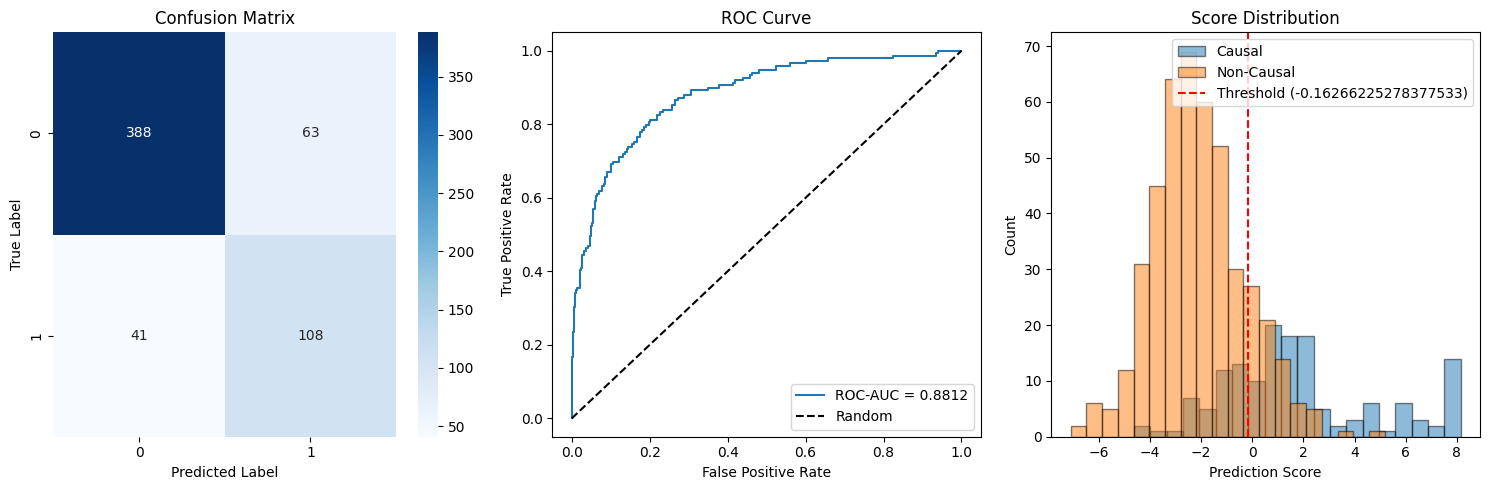


OK Plots saved to models/causal_classifier/causal_crossencoder_v1/evaluation_plots.png


In [21]:
# Cell 19: Visualize Results

from sklearn.metrics import confusion_matrix, roc_curve

plt.figure(figsize=(15, 5))

# Plot 1: Confusion Matrix
plt.subplot(1, 3, 1)
cm = confusion_matrix(holdout_labels, holdout_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')

# Plot 2: ROC Curve
plt.subplot(1, 3, 2)
fpr, tpr, thresholds = roc_curve(holdout_labels, holdout_scores)
plt.plot(fpr, tpr, label=f'ROC-AUC = {roc_auc:.4f}')
plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()

# Plot 3: Score Distribution
plt.subplot(1, 3, 3)
causal_scores = holdout_scores[holdout_labels == 1]
non_causal_scores = holdout_scores[holdout_labels == 0]
plt.hist(causal_scores, bins=20, alpha=0.5, label='Causal', edgecolor='black')
plt.hist(non_causal_scores, bins=20, alpha=0.5, label='Non-Causal', edgecolor='black')
plt.axvline(x=threshold, color='r', linestyle='--', label=f'Threshold ({threshold})')
plt.xlabel('Prediction Score')
plt.ylabel('Count')
plt.title('Score Distribution')
plt.legend()

plt.tight_layout()
plt.savefig(f"{MODEL_SAVE_PATH}/evaluation_plots.png", dpi=150, bbox_inches='tight')
plt.show()

print(f"\nOK Plots saved to {MODEL_SAVE_PATH}/evaluation_plots.png")

## Section 8: Inference & Root Cause Detection

In [22]:
# Cell 20: Load Trained Model for Inference

# Load for inference
model_path = Path(MODEL_SAVE_PATH)
config_path = model_path / "config.json"

if config_path.exists():
    trained_model = CrossEncoder(MODEL_SAVE_PATH, max_length=MAX_SEQ_LENGTH)
    print(f"OK Loaded trained model from {MODEL_SAVE_PATH}")
else:
    if 'model' in globals():
        trained_model = model
        print("NOTE: Trained model files not found on disk; using in-memory model. Run training cell to save.")
    else:
        print("WARN: Trained model not found; loading base model for inference.")
        trained_model = CrossEncoder('cross-encoder/ms-marco-MiniLM-L-12-v2', num_labels=1, max_length=MAX_SEQ_LENGTH)
        print("OK Loaded base model: cross-encoder/ms-marco-MiniLM-L-12-v2 (12-layer)")

OK Loaded trained model from models/causal_classifier/causal_crossencoder_v1


In [23]:
# Cell 21: Detect Causality Function

def detect_causality(incident_a_id, incident_b_id, return_direction=True):
    """
    Detect if incident A caused incident B.

    Args:
        incident_a_id: Incident number (e.g., 'INC0012345')
        incident_b_id: Incident number (e.g., 'INC0012389')
        return_direction: Include bidirectional analysis

    Returns:
        dict with causal (bool), confidence (float), direction (str)
    """
    # Get texts
    row_a = df[df['Number'] == incident_a_id]
    row_b = df[df['Number'] == incident_b_id]

    if row_a.empty or row_b.empty:
        return {'error': 'Incident not found'}

    text_a = str(row_a.iloc[0]['Description'])
    text_b = str(row_b.iloc[0]['Description'])

    a_time = row_a.iloc[0]['Created_dt']
    b_time = row_b.iloc[0]['Created_dt']
    cat_a = row_a.iloc[0]['Category']
    cat_b = row_b.iloc[0]['Category']
    meta_ab = make_meta(a_time, b_time, cat_a, cat_b)
    meta_ba = make_meta(b_time, a_time, cat_b, cat_a)

    # Predict both directions
    text_ab = format_pair(text_a, text_b, meta_ab)
    score_ab = trained_model.predict([list(text_ab)])[0]
    text_ba = format_pair(text_b, text_a, meta_ba)
    score_ba = trained_model.predict([list(text_ba)])[0]

    # Determine causality
    threshold = DEFAULT_CAUSAL_THRESHOLD

    if score_ab > threshold and score_ba > threshold:
        direction = "bidirectional"
        causal = True
        confidence = (score_ab + score_ba) / 2
    elif score_ab > threshold:
        direction = "A->B"
        causal = True
        confidence = score_ab
    elif score_ba > threshold:
        direction = "B->A"
        causal = True
        confidence = score_ba
    else:
        direction = "none"
        causal = False
        confidence = max(score_ab, score_ba)

    return {
        'causal': causal,
        'confidence': float(confidence),
        'direction': direction,
        'scores': {
            'a_caused_b': float(score_ab),
            'b_caused_a': float(score_ba)
        }
    }

print("OK detect_causality() function ready")

OK detect_causality() function ready


In [24]:
# Cell 22: Find Root Causes Function

def find_root_causes(incident_id, time_window_hours=24, top_k=10):
    """
    Find potential root causes for a given incident.

    Args:
        incident_id: Target incident number
        time_window_hours: Look back window in hours
        top_k: Number of top candidates to return

    Returns:
        List of potential root cause incidents with scores
    """
    target = df[df['Number'] == incident_id]

    if target.empty:
        return {'error': 'Incident not found'}

    target = target.iloc[0]
    target_time = target['Created_dt']
    target_text = str(target['Description'])

    if pd.isna(target_time):
        return {'error': 'Incident has no creation timestamp'}

    # Find candidates (created before target, within time window)
    window_start = target_time - timedelta(hours=time_window_hours)
    mask = (df['Created_dt'] >= window_start) & (df['Created_dt'] < target_time)
    candidates = df[mask].copy()

    print(f"Found {len(candidates)} candidates within {time_window_hours}h before {incident_id}")

    if len(candidates) == 0:
        return []

    # Score all candidates
    results = []
    for idx, candidate in tqdm(candidates.iterrows(), total=len(candidates), desc="Scoring candidates"):
        candidate_text = str(candidate['Description'])
        meta = make_meta(candidate['Created_dt'], target_time, candidate['Category'], target['Category'])
        text_pair = format_pair(candidate_text, target_text, meta)
        score = trained_model.predict([list(text_pair)])[0]

        results.append({
            'candidate_id': candidate['Number'],
            'description': candidate_text[:100] + "..." if len(candidate_text) > 100 else candidate_text,
            'category': candidate['Category'],
            'causal_score': float(score),
            'time_diff_hours': (target_time - candidate['Created_dt']).total_seconds() / 3600
        })

    # Sort by score
    results.sort(key=lambda x: x['causal_score'], reverse=True)

    return results[:top_k]

print("OK find_root_causes() function ready")

OK find_root_causes() function ready


In [25]:
# Cell 23: Test Causality Detection

# Get two random incidents for testing
test_incidents = df.sample(2)
incident_a = test_incidents.iloc[0]['Number']
incident_b = test_incidents.iloc[1]['Number']

print(f"Testing causality detection between:")
print(f"  A: {incident_a}")
print(f"  B: {incident_b}")
print()

result = detect_causality(incident_a, incident_b)

print("Result:")
print(json.dumps(result, indent=2))

Testing causality detection between:
  A: INC0058354
  B: INC0010618

Result:
{
  "causal": false,
  "confidence": -0.9815609455108643,
  "direction": "none",
  "scores": {
    "a_caused_b": -4.085423469543457,
    "b_caused_a": -0.9815609455108643
  }
}


In [26]:
# Cell 24: Test Root Cause Finding

# Get a random incident for testing
test_incident = df[df['Created_dt'].notna()].sample(1).iloc[0]['Number']

print(f"Finding root causes for: {test_incident}")
print()

root_causes = find_root_causes(test_incident, time_window_hours=24, top_k=5)

if isinstance(root_causes, dict) and 'error' in root_causes:
    print(f"Error: {root_causes['error']}")
elif len(root_causes) == 0:
    print("No candidates found in time window")
else:
    print(f"Top {len(root_causes)} potential root causes:\n")
    for i, rc in enumerate(root_causes, 1):
        print(f"{i}. {rc['candidate_id']} (score: {rc['causal_score']:.4f}, {rc['time_diff_hours']:.1f}h ago)")
        print(f"   Category: {rc['category']}")
        print(f"   {rc['description']}")
        print()

Finding root causes for: INC0031148

Found 14 candidates within 24h before INC0031148


Scoring candidates:   0%|          | 0/14 [00:00<?, ?it/s]

Top 5 potential root causes:

1. INC0026898 (score: 0.5309, 14.2h ago)
   Category: Application/Software
   Please check eTravel document PTLAP204912 Posting Failure.

2. INC0026823 (score: -0.3286, 21.9h ago)
   Category: Application/Software
   SI-250059 has invoice K24TSS;00008807 but wrong date => Please correct

3. INC0026853 (score: -1.0524, 19.4h ago)
   Category: Application/Software
   PSI interface data is not reaching to EYESG21 for last few months. Please analyze whether any issue ...

4. INC0026894 (score: -1.7872, 15.7h ago)
   Category: Application/Software
   Please check we cannot see order PSV-EWS-2407000185 in SAP and V-invoice

5. INC0026868 (score: -2.0273, 18.4h ago)
   Category: Application/Software
   Kindly Please help for this Issue :
PGI-SO-2407001929  is appear In SAP System, But in SFDC is not ...



In [27]:
# Cell 25: Build Dependency Graph Function

def build_dependency_graph(incident_ids, time_window_hours=24, min_score=0.5):
    """
    Build a dependency graph for a set of incidents.

    Args:
        incident_ids: List of incident numbers
        time_window_hours: Time window for causality
        min_score: Minimum causal score threshold

    Returns:
        Dict with nodes and edges for graph visualization
    """
    nodes = []
    edges = []

    # Get incident data
    incidents = df[df['Number'].isin(incident_ids)].copy()
    incidents = incidents.sort_values('Created_dt')

    print(f"Building dependency graph for {len(incidents)} incidents...")

    # Create nodes
    for idx, inc in incidents.iterrows():
        nodes.append({
            'id': inc['Number'],
            'description': str(inc['Description'])[:100] + "...",
            'category': inc['Category'],
            'created': str(inc['Created_dt'])
        })

    # Check all pairs for causality
    for i, inc_a in incidents.iterrows():
        for j, inc_b in incidents.iterrows():
            if inc_a['Number'] == inc_b['Number']:
                continue

            # Check temporal ordering
            if pd.notna(inc_a['Created_dt']) and pd.notna(inc_b['Created_dt']):
                time_diff = (inc_b['Created_dt'] - inc_a['Created_dt']).total_seconds() / 3600

                # Only check if A happened before B and within time window
                if 0 < time_diff <= time_window_hours:
                    result = detect_causality(inc_a['Number'], inc_b['Number'])

                    if result.get('causal') and result['scores']['a_caused_b'] >= min_score:
                        edges.append({
                            'source': inc_a['Number'],
                            'target': inc_b['Number'],
                            'score': result['scores']['a_caused_b'],
                            'time_diff_hours': time_diff
                        })

    print(f"\nOK Graph built: {len(nodes)} nodes, {len(edges)} edges")

    return {
        'nodes': nodes,
        'edges': edges
    }

print("OK build_dependency_graph() function ready")

OK build_dependency_graph() function ready


Building dependency graph for 10 incidents from same time period...

Building dependency graph for 10 incidents...

OK Graph built: 10 nodes, 1 edges

Edges (causal relationships):
  INC0034630 -> INC0034669 (score: 1.9186, 4.0h)


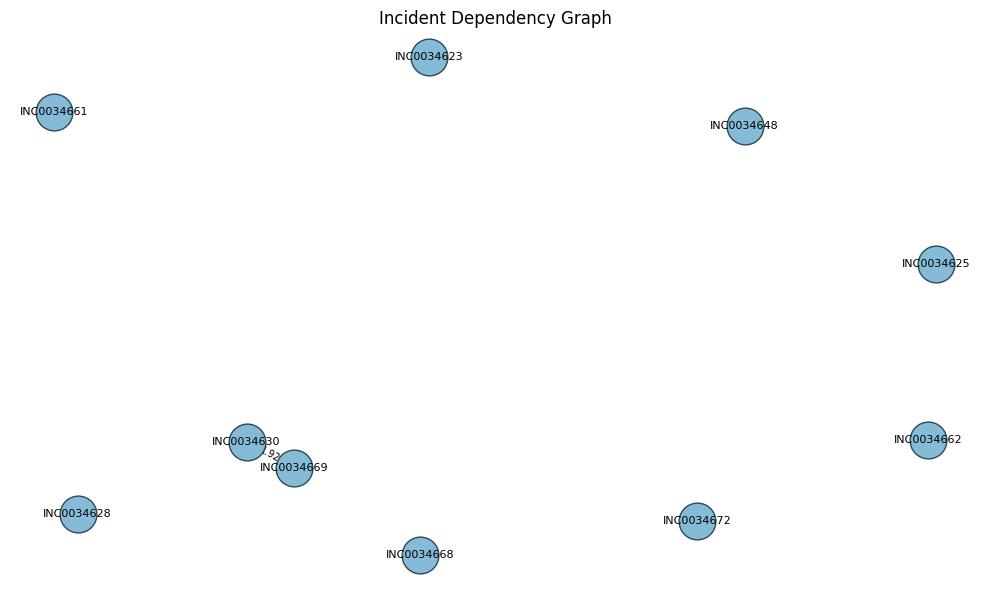

In [28]:
# Cell 26: Test Dependency Graph

# Get a set of incidents from the same time period
sample_time = df[df['Created_dt'].notna()].sample(1).iloc[0]['Created_dt']
time_window_start = sample_time - timedelta(hours=6)
time_window_end = sample_time + timedelta(hours=6)

sample_incidents = df[
    (df['Created_dt'] >= time_window_start) & 
    (df['Created_dt'] <= time_window_end)
].head(10)['Number'].tolist()

print(f"Building dependency graph for {len(sample_incidents)} incidents from same time period...")
print()

graph = build_dependency_graph(sample_incidents, time_window_hours=12, min_score=0.5)

print("\nEdges (causal relationships):")
for edge in graph['edges']:
    print(f"  {edge['source']} -> {edge['target']} (score: {edge['score']:.4f}, {edge['time_diff_hours']:.1f}h)")

if len(graph['edges']) == 0:
    print("  No causal relationships found above threshold")

# Visualize dependency graph
try:
    import networkx as nx

    if len(graph['nodes']) > 0:
        G = nx.DiGraph()
        for node in graph['nodes']:
            G.add_node(node['id'], category=node.get('category'))
        for edge in graph['edges']:
            G.add_edge(edge['source'], edge['target'], weight=edge['score'])

        plt.figure(figsize=(10, 6))
        pos = nx.spring_layout(G, seed=42)
        nx.draw_networkx_nodes(G, pos, node_size=700, node_color="#86BBD8", edgecolors="#2F4858")
        nx.draw_networkx_edges(G, pos, arrows=True, arrowstyle="-|>", arrowsize=14, edge_color="#2F4858")
        nx.draw_networkx_labels(G, pos, font_size=8)

        edge_labels = {(u, v): f"{d['weight']:.2f}" for u, v, d in G.edges(data=True)}
        nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=7)

        plt.title("Incident Dependency Graph")
        plt.axis("off")
        plt.tight_layout()
        plt.show()
    else:
        print("No nodes to visualize")
except ImportError:
    print("NOTE: networkx not installed; skipping graph visualization. Install with: pip install networkx")

## Summary & Next Steps

**Completed:**
1. OK Extracted causal pairs using 3 methods (parent/child, resolution notes, temporal+similarity)
2. OK Generated balanced non-causal pairs (hard negatives)
3. OK Trained CrossEncoder model for causal classification
4. OK Evaluated model with ROC-AUC, F1, and directionality metrics
5. OK Created inference functions for causality detection and root cause finding
6. OK Built dependency graph construction capability

**Usage:**
```python
# Detect if A caused B
result = detect_causality('INC0012345', 'INC0012389')

# Find root causes for an incident
root_causes = find_root_causes('INC0012389', time_window_hours=24, top_k=10)

# Build dependency graph
graph = build_dependency_graph(incident_list, time_window_hours=24, min_score=0.5)
```

**Next Steps:**
- Integrate with production API (similar to reranking endpoint)
- Create visualization dashboard for dependency graphs
- Monitor model performance on real-world data
- Iterate on extraction methods to improve training data quality